# Atlas-DeePC: projection-regularization ablation

**Our original offline dataset (±1 exploration), p=8, no graph guidance, K=64, rank 53.**
Development seeds **211–310**, **300 controlled steps**, \(T_{\mathrm{ini}}=2\), \(T_{\mathrm f}=10\), and 12 zero-input warmup steps.

This is a new experiment—not the 94%-success Select-DPC-data experiment. All generated data, the shared atlas, projector diagnostics and results are stored under **~/Projects/atlas_proj_reg_data**, outside the project. Execution is disabled by default.

Only \(\lambda_\Pi\) changes. All candidates use the same frozen own-data atlas, exact reduced bases, unstandardized coordinates, fixed-nearest eligible p=8 reference rule, resets, warmup, constraints and other weights. The zero-penalty case is rerun as the paired control; historical results are not imported.

## Projection in reduced Atlas coordinates

A chart has an orthonormal basis \(B_k\in\mathbb R^{120\times53}\), not selected raw Hankel columns. Its stored rows are
\[
B_k=[B_{u,p};B_{u,f};B_{y,p};B_{y,f}].
\]
Define
\[
M_k=[B_{u,p};B_{y,p};B_{u,f}]\in\mathbb R^{40\times53},
\quad \Pi_k=M_k^\dagger M_k,\quad
\lambda_\Pi\|(I-\Pi_k)g\|_2^2=\lambda_\Pi\|N_k^\top g\|_2^2,
\]
where \(N_k\) is an orthonormal basis of \(\ker M_k\). The penalty suppresses coefficient directions that change future outputs without changing the represented past input/output or future inputs.

**No \(\mathbf1^\top\) row and no \(\mathbf1^\top g=1\) constraint:** these are linear subspace coordinates, not affine raw-column coefficients. This is an analogous penalty, **not numerically the same penalty/scale as Select-DPC's raw-column regularizer**. It is invariant under orthogonal rotations of the retained basis, but not arbitrary coefficient rescaling.

The controller solves
\[
\begin{aligned}
\min_{g,u^f,y^f,\sigma}\quad&
\|y^f-y^{ref}\|_{I_{10}\otimes Q}^2+
\|u^f\|_{I_{10}\otimes R}^2+
10^5\|\sigma\|_2^2+\lambda_\Pi\|N_k^\top g\|_2^2\\
\text{s.t.}\quad&
B_k g=[u_{\mathrm{ini}};u^f;y_{\mathrm{ini}}+\sigma;y^f],\quad -1\le u^f\le1,
\end{aligned}
\]
with \(Q=\operatorname{diag}(5000,5000,5000,5000,20,20,10^5,10^5)\), \(R=10^{-4}I_2\).
No L1 coefficient penalty, coefficient box, input-increment penalty or graph waypoint is added.

The SVD of \(M_k\) is computed **offline** using relative numerical-rank tolerance \(10^{-10}\). This determines the projector, not the retained chart rank (53). If \(M_k\) has full column rank, the penalty is zero; it is not ordinary ridge regularization.

In [1]:
from pathlib import Path
import os, sys, json, subprocess, signal
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[name] = "1"
os.environ.setdefault("MPLCONFIGDIR", "/tmp/atlas_proj_reg_mpl")
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/atlas_deepc/ablations/projection_regularization.py").is_file())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from atlas_deepc.ablations import projection_regularization as study

OUTPUT_ROOT = Path.home() / "Projects/atlas_proj_reg_data/own_data_p8_k64_r53_t300_v1"
DATA_PATH = ROOT / "data/reacher/select_iid_offline_hankel.npy"  # OUR dataset: legacy filename.
LAMBDAS = [0, 1, 10, 100, 1000, 10000]
T_sim = 300
BATCH_SIZE = 100                  # All development seeds PER lambda; 600 total rollouts.
BLOCK_START, BLOCK_STOP = 211, 310
PREPARE_ONLY = False
RUN_EXPERIMENT = False

assert T_sim == 300, "Use a separate output root for shorter smoke runs."
assert DATA_PATH.is_file(), f"Our offline dataset is unavailable: {DATA_PATH}"
assert not OUTPUT_ROOT.resolve().is_relative_to(ROOT.parent.resolve())
assert 211 <= BLOCK_START <= BLOCK_STOP <= 310 and BATCH_SIZE > 0
print("Own offline dataset:", DATA_PATH)
print("Output root:", OUTPUT_ROOT)
print(f"Full design: {len(LAMBDAS)} × 100 = {len(LAMBDAS)*100} rollouts; {T_sim} steps each.")
display(pd.DataFrame({
    "lambda_pi": LAMBDAS,
    "Full-panel seeds": [100]*len(LAMBDAS),
    "Max new rollouts this invocation": [min(BATCH_SIZE, BLOCK_STOP-BLOCK_START+1)]*len(LAMBDAS),
    "Role": ["Paired unregularized control" if x==0 else "Projection-penalty candidate" for x in LAMBDAS],
}))
print("This candidate grid does not imply a tuning outcome.")

Own offline dataset: /Users/kumiko/Projects/atlas_deepc/code/data/reacher/select_iid_offline_hankel.npy
Output root: /Users/kumiko/Projects/atlas_proj_reg_data/own_data_p8_k64_r53_t300_v1
Full design: 6 × 100 = 600 rollouts; 300 steps each.


,lambda_pi,Full-panel seeds,Max new rollouts this invocation,Role
0,0,100,100,Paired unregularized control
1,1,100,100,Projection-penalty candidate
2,10,100,100,Projection-penalty candidate
3,100,100,100,Projection-penalty candidate
4,1000,100,100,Projection-penalty candidate
5,10000,100,100,Projection-penalty candidate


This candidate grid does not imply a tuning outcome.


## Offline diagnostics — read-only

Preparation copies our existing data and fits one shared atlas; it does not collect new data or simulate controlled rollouts. Every candidate reuses those assets. K=64 and rank=53 are inherited from our original Atlas development setup, not retuned per candidate.

In [2]:
diagnostic_path = OUTPUT_ROOT / "shared/projection_diagnostics.json"
if diagnostic_path.exists():
    diagnostic = pd.DataFrame(json.loads(diagnostic_path.read_text()))
    display(diagnostic.groupby(["rank","M_rank","nullity"]).size().reset_index(name="Number of charts"))
    print(f"Max ||M N||_F: {diagnostic.annihilation_residual.max():.3e}")
    print(f"Projector rank tolerance: {study.RTOL:g}")
    print("Projectors are computed offline, not during online controller timing.")
else:
    print("Not prepared. Set PREPARE_ONLY=True and RUN_EXPERIMENT=True to build offline assets only.")

,rank,M_rank,nullity,Number of charts
0,53,40,13,64


Max ||M N||_F: 1.856e-15
Projector rank tolerance: 1e-10
Projectors are computed offline, not during online controller timing.


## Run/resume a serial batch

Set `RUN_EXPERIMENT=True`, then execute the settings and launch cells. Return it to `False` when viewing results.

- Current setting: **100 development seeds per candidate = 600 rollouts** in total.
- `BATCH_SIZE=100`: request the full **600-rollout sweep**.
- `LAMBDAS=[0,1000]`: run just those two candidates.
- Use the same `BLOCK_START`/`BLOCK_STOP` for paired comparisons. Completed seeds are validated and skipped; an interrupted seed restarts.
- `PREPARE_ONLY=True`: prepare data/atlas/projectors without rollouts.

No follow-up batches are launched automatically. A root lock prevents duplicate sweep workers. Keep the laptop awake, and avoid competing workloads for meaningful timings. Do not change controller source/frozen settings between batches; use a new output root when changing the protocol.

Timing pools steps 6–300. Offline clustering/SVD/projector construction, environment stepping and file writes are excluded; regularized QP construction and solving are included.

In [3]:
command = [sys.executable, "-u", "-m", "atlas_deepc.ablations.projection_regularization",
           "--output", str(OUTPUT_ROOT), "--data", str(DATA_PATH),
           "--steps", str(T_sim), "--batch-size", str(BATCH_SIZE),
           "--block-start", str(BLOCK_START), "--block-stop", str(BLOCK_STOP),
           "--lambdas", *[str(x) for x in LAMBDAS]]
if PREPARE_ONLY:
    command.append("--prepare-only")
if not RUN_EXPERIMENT:
    print("Not launched. Set RUN_EXPERIMENT=True to run the requested batch.")
    print(" ".join(command))
else:
    process = subprocess.Popen(command, cwd=ROOT,
        env=dict(os.environ, PYTHONPATH=str(ROOT / "src")),
        stdin=subprocess.DEVNULL, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, bufsize=1, start_new_session=True)
    try:
        for line in process.stdout:
            print(line, end="", flush=True)
        if process.wait():
            raise RuntimeError("Run stopped; inspect the error above. Completed seeds are preserved.")
    except KeyboardInterrupt:
        if process.poll() is None:
            process.send_signal(signal.SIGINT)
            try:
                process.wait(timeout=20)
            except subprocess.TimeoutExpired:
                print(f"PID {process.pid} is still stopping; do not start another worker.")
        raise
    finally:
        process.stdout.close()

Not launched. Set RUN_EXPERIMENT=True to run the requested batch.
/Users/kumiko/miniconda3/envs/gym-robotics-mujoco/bin/python -u -m atlas_deepc.ablations.projection_regularization --output /Users/kumiko/Projects/atlas_proj_reg_data/own_data_p8_k64_r53_t300_v1 --data /Users/kumiko/Projects/atlas_deepc/code/data/reacher/select_iid_offline_hankel.npy --steps 300 --batch-size 100 --block-start 211 --block-stop 310 --lambdas 0 1 10 100 1000 10000


## Saved results — no simulation

Success requires **both** final-30 and final-100 mean fingertip errors <10 mm and maxima <20 mm. Final-window error is the median across rollouts of each rollout's final-100 mean. Full-rollout RMSE includes the initial reaching transient.

The unweighted projection norm is \(\|N_k^\top g\|_2^2\), pooled over solved steps (including the first five). The weighted penalty and full QP objective are saved separately. Realized tracking/input cost does **not** include the optimization regularizer.

Compare candidates on the same completed seeds. A partial candidate is not directly comparable to a full panel. The paired table verifies identical final references and warmup histories; negative error differences favor regularization.

In [2]:
saved = study.sweep_report(OUTPUT_ROOT, LAMBDAS)
results = pd.DataFrame(saved["panels"])
display(results.rename(columns={
    "completed":"Completed / 100", "successes":"Successes",
    "success_rate":"Success fraction", "median_final100_error_mm":"Median final100 error (mm)",
    "median_rollout_rmse_mm":"Median rollout RMSE (mm)", "median_online_ms":"Median time (ms)",
    "p95_online_ms":"P95 time (ms)", "unsolved_steps":"Unsolved steps",
    "median_projection_norm_squared":"Median projection norm²",
}).drop(columns="requested").style.hide(axis="index").format(precision=3,na_rep="—"))
pairs = pd.DataFrame(saved["paired_deltas"])
if len(pairs):
    paired_table = pairs.groupby("lambda_pi").agg(
        matched_seeds=("seed","size"),
        median_error_difference_mm=("delta_final100_mm","median"),
        improved_seeds=("delta_final100_mm",lambda x:int((x<0).sum())),
    ).reset_index()
    display(Markdown("### Paired final-window error differences versus lambda=0"))
    display(paired_table.style.hide(axis="index").format({"median_error_difference_mm":"{:.3f}"}))
else:
    print("No matched completed rollouts yet. Prepared assets and smoke tests are not evaluation results.")

lambda_pi,Completed / 100,Successes,Success fraction,Median final100 error (mm),Median rollout RMSE (mm),Median time (ms),P95 time (ms),Unsolved steps,Median projection norm²
0.000,100,90,0.900,1.781,61.675,19.030,25.039,0,12.722
1.000,100,90,0.900,1.782,61.675,19.897,25.106,0,12.715
10.000,100,89,0.890,1.780,61.687,19.340,23.230,0,12.354
100.000,100,88,0.880,1.785,61.788,18.821,23.066,0,11.588
1000.000,100,80,0.800,2.111,62.663,19.048,22.974,0,8.403
10000.000,100,74,0.740,3.173,67.279,19.801,25.367,0,1.421


### Paired final-window error differences versus lambda=0

lambda_pi,matched_seeds,median_error_difference_mm,improved_seeds
1.000000,100,0.000,46
10.000000,100,0.003,44
100.000000,100,0.010,47
1000.000000,100,0.142,36
10000.000000,100,1.470,20


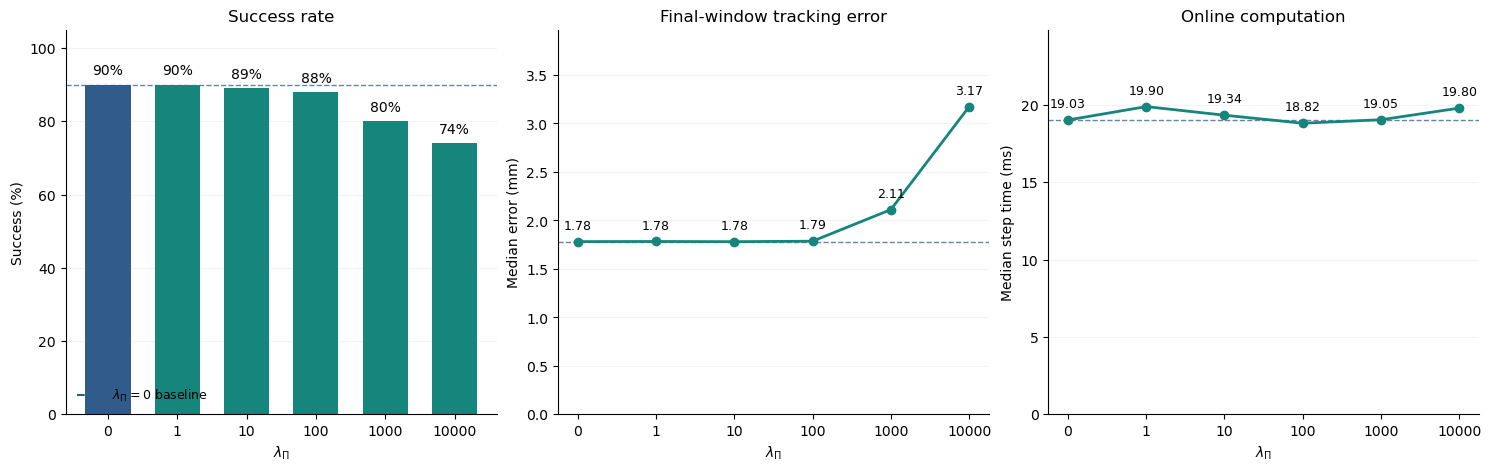

Success: both final-30 and final-100 windows require mean <10 mm and maximum <20 mm.
Error: median across rollouts of the final-100-step mean. Timing: pooled steps 6–300.
No uncertainty intervals are shown. This is a development-set comparison.
Saved figures: /Users/kumiko/Projects/atlas_proj_reg_data/own_data_p8_k64_r53_t300_v1/figures


In [3]:
# Plot completed panels only; all values come from validated saved traces.
complete = results[(results.completed == 100) & results.success_rate.notna()].sort_values("lambda_pi").copy()
if len(complete):
    x = np.arange(len(complete))
    labels = [f"{v:g}" for v in complete.lambda_pi]
    baseline = complete.loc[complete.lambda_pi == 0]
    colors = ["#315b8a" if v == 0 else "#16857b" for v in complete.lambda_pi]
    fig, axes = plt.subplots(1, 3, figsize=(14.8, 4.6), layout="constrained")
    success_pct = 100 * complete.success_rate.to_numpy()
    bars = axes[0].bar(x, success_pct, color=colors, width=.65)
    axes[0].bar_label(bars, labels=[f"{v:.0f}%" for v in success_pct], padding=5, fontsize=10)
    axes[0].set(title="Success rate", ylabel="Success (%)", ylim=(0, 105))
    errors = complete.median_final100_error_mm.to_numpy()
    axes[1].plot(x, errors, "o-", color="#16857b", linewidth=2, markersize=6)
    for xi, y in zip(x, errors):
        axes[1].annotate(f"{y:.2f}", (xi, y), xytext=(0, 9), textcoords="offset points",
                         ha="center", fontsize=9)
    axes[1].set(title="Final-window tracking error", ylabel="Median error (mm)",
                ylim=(0, max(errors)*1.25))
    times = complete.median_online_ms.to_numpy()
    axes[2].plot(x, times, "o-", color="#16857b", linewidth=2, markersize=6)
    for xi, y in zip(x, times):
        axes[2].annotate(f"{y:.2f}", (xi, y), xytext=(0, 9), textcoords="offset points",
                         ha="center", fontsize=9)
    axes[2].set(title="Online computation", ylabel="Median step time (ms)",
                ylim=(0, max(times)*1.25))
    if len(baseline):
        reference = baseline.iloc[0]
        for ax, y in zip(axes, [100*reference.success_rate,
                                reference.median_final100_error_mm, reference.median_online_ms]):
            ax.axhline(y, color="#315b8a", ls="--", lw=1, alpha=.75, zorder=0)
        axes[0].plot([], [], color="#315b8a", ls="--", label=r"$\lambda_\Pi=0$ baseline")
        axes[0].legend(loc="lower left", frameon=False, fontsize=9)
    for ax in axes:
        ax.set_xticks(x, labels)
        ax.set_xlabel(r"$\lambda_\Pi$")
        ax.grid(axis="y", alpha=.15)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
    FIGURE_DIR = OUTPUT_ROOT / "figures"
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURE_DIR / "projection_regularization_summary.png", dpi=180, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / "projection_regularization_summary.pdf", bbox_inches="tight")
    plt.show()
    print("Success: both final-30 and final-100 windows require mean <10 mm and maximum <20 mm.")
    print("Error: median across rollouts of the final-100-step mean. Timing: pooled steps 6–300.")
    print("No uncertainty intervals are shown. This is a development-set comparison.")
    print("Saved figures:", FIGURE_DIR)
else:
    print("No complete 100-seed panels yet; partial panels are not plotted as full results.")

## Inspect a paired rollout

Change the seed and candidate below after both traces exist. Saved data include predicted horizons, coefficients, slack, exact bases, projector diagnostics, statuses, projection norm, weighted penalty and base/total QP objective. Historical experiments and separate smoke-test results are never included automatically.

In [6]:
PLOT_SEED = 211
PLOT_LAMBDA = 1000
paths = [study.panel_directory(OUTPUT_ROOT,v)/f"seed{PLOT_SEED}_control_results.npz"
         for v in (0,PLOT_LAMBDA)]
if all(p.exists() for p in paths):
    fig,axes = plt.subplots(1,3,figsize=(14,4),constrained_layout=True)
    for value,path in zip((0,PLOT_LAMBDA),paths):
        with np.load(path,allow_pickle=True) as trace:
            label=f"lambda={value:g}"
            axes[0].plot(trace["distance"]*1000,label=label)
            axes[1].plot(trace["projection_norm_squared"],label=label)
            axes[2].plot(trace["control_compute_time_s"]*1000,label=label)
    axes[0].set(title=f"Seed {PLOT_SEED}: target error",ylabel="mm")
    axes[1].set(title="Unweighted projection norm²")
    axes[2].set(title="Online computation",ylabel="ms")
    for ax in axes:
        ax.set_xlabel("Control step"); ax.legend()
    plt.show()
else:
    print("Both saved traces are required; no rollout is launched by this cell.")

Both saved traces are required; no rollout is launched by this cell.
